In [20]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [21]:
#Define State 
class BmiState(TypedDict) :
    weight_kg : float
    height_m : float
    bmi : float
    category : str

In [22]:
#Create function to calculate bmi 
def calculate_bmi(state : BmiState) -> BmiState : 
    w = state['weight_kg']
    h = state['height_m']

    bmi = w/(h ** 2)

    state['bmi'] = round(bmi, 2)
    return state

In [23]:
# Function for find category
def bmi_category(state : BmiState) -> BmiState :
    cat = state['bmi']

    if cat < 18.5:
        state['category'] = "Underweight"
    elif 18.5 <= cat < 25:
        state['category'] = "Normal"
    elif 25 <= cat < 30:
        state['category'] = "Overweight"
    else:
        state['category'] = "Obese"

    return state

In [24]:
# Define Graph
graph = StateGraph(BmiState)

# Add nodes to graph
graph.add_node('cal_bmi', calculate_bmi)
graph.add_node('cat_bmi', bmi_category)

# Add edges to graph
graph.add_edge(START, 'cal_bmi')
graph.add_edge('cal_bmi', 'cat_bmi')
graph.add_edge('cat_bmi', END)

workflow = graph.compile()

In [25]:
# Final Output
initial_state = {'weight_kg' : 80, 'height_m' : 1.73}

final_state = workflow.invoke(initial_state)

print(final_state)

{'weight_kg': 80, 'height_m': 1.73, 'bmi': 26.73, 'category': 'Overweight'}


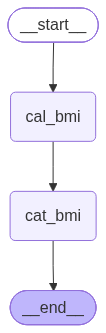

In [26]:
# Print Workflow Diagram
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())